# Лабораторная работа 2. Рекомендательные системы

В качестве основы работы выбрано соревнование **VK-LSVD** ([VK RecSys Challenge / ODS](https://ods.ai/competitions/vkrecsyschallengelsvd)).


В работе используются недели `week_00`–`week_13` (train), `week_14` (validation) и `week_15` (test). Validation нужна для выбора гиперпараметров, test в подборе не участвует.


## 0. Загрузка данных

In [1]:
from pathlib import Path
from huggingface_hub import hf_hub_download

DATA_DIR = Path("VK-LSVD")
SUBSAMPLE = "up0.001_ip0.001"

for i in range(15):
    hf_hub_download(
        repo_id="deepvk/VK-LSVD",
        repo_type="dataset",
        filename=f"subsamples/{SUBSAMPLE}/train/week_{i:02d}.parquet",
        local_dir=str(DATA_DIR),
    )

hf_hub_download(
    repo_id="deepvk/VK-LSVD",
    repo_type="dataset",
    filename=f"subsamples/{SUBSAMPLE}/train/week_15.parquet",
    local_dir=str(DATA_DIR),
)

for f in ["metadata/users_metadata.parquet", "metadata/items_metadata.parquet"]:
    hf_hub_download(
        repo_id="deepvk/VK-LSVD",
        repo_type="dataset",
        filename=f,
        local_dir=str(DATA_DIR),
    )

print("OK:", DATA_DIR.resolve())

D:\PyCharmProjects\DataAnalys\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OK: D:\PyCharmProjects\DataAnalys\lab2\VK-LSVD


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
K_LIST = (10, 20, 50, 100)
K = 50  # основной K
POS_TIMESPENT = 15  # порог вовлечённого просмотра

## 1. Загрузка и первичный обзор

In [3]:
train_dir = DATA_DIR / "subsamples" / SUBSAMPLE / "train"
VAL_WEEK = 14
TEST_WEEK = 15
holdout = {f"week_{VAL_WEEK:02d}", f"week_{TEST_WEEK:02d}"}

train_files = sorted(f for f in train_dir.glob("week_*.parquet") if f.stem not in holdout)
train_raw = pl.concat([pl.scan_parquet(str(f)) for f in train_files]).collect(engine="streaming")
val_raw = pl.read_parquet(train_dir / f"week_{VAL_WEEK:02d}.parquet")
test_raw = pl.read_parquet(train_dir / f"week_{TEST_WEEK:02d}.parquet")

users_meta = pl.read_parquet(DATA_DIR / "metadata" / "users_metadata.parquet")
items_meta = pl.read_parquet(DATA_DIR / "metadata" / "items_metadata.parquet")

print(f"Train week_00–week_{VAL_WEEK - 1:02d}: {train_raw.height:,} rows | users={train_raw['user_id'].n_unique():,} | items={train_raw['item_id'].n_unique():,}")
print(f"Val   week_{VAL_WEEK:02d}: {val_raw.height:,} rows | users={val_raw['user_id'].n_unique():,} | items={val_raw['item_id'].n_unique():,}")
print(f"Test  week_{TEST_WEEK:02d}: {test_raw.height:,} rows | users={test_raw['user_id'].n_unique():,} | items={test_raw['item_id'].n_unique():,}")
print("Колонки:", train_raw.columns)
train_raw.head()


Train week_00–week_13: 23,877,602 rows | users=10,000 | items=14,635
Val   week_14: 2,477,078 rows | users=9,992 | items=10,449
Test  week_15: 2,519,820 rows | users=9,999 | items=10,639
Колонки: ['user_id', 'item_id', 'place', 'platform', 'agent', 'timespent', 'like', 'dislike', 'share', 'bookmark', 'click_on_author', 'open_comments']


user_id,item_id,place,platform,agent,timespent,like,dislike,share,bookmark,click_on_author,open_comments
u32,u32,u8,u8,u8,u8,bool,bool,bool,bool,bool,bool
141827770,160593626,1,1,1,56,false,false,false,false,false,false
468779351,327484273,1,0,0,1,false,false,false,false,false,false
494341617,402842289,1,0,0,11,false,false,false,false,false,false
453833313,102672169,0,0,0,45,false,false,false,false,false,false
154047442,139795075,1,0,0,39,false,false,false,false,false,false


### Схема данных
Каждая строка — показ короткого видео пользователю (без повторных показов одной пары `user–item`).

| Поле | Описание |
|------|----------|
| `user_id`, `item_id` | анонимизированные ID |
| `place`, `platform`, `agent` | контекст показа |
| `timespent` | длительность просмотра, 0–255 сек |
| `like`, `dislike`, `share`, `bookmark`, `click_on_author`, `open_comments` | сигналы обратной связи |

Метаданные: у пользователей — `age`, `gender`, `geo`; у видео — `author_id`, `duration`.

## 2. Разведочный анализ (EDA)

In [4]:
train_users = train_raw.select("user_id").unique()
train_items = train_raw.select("item_id").unique()
users_s = users_meta.join(train_users, on="user_id")
items_s = items_meta.join(train_items, on="item_id")
print("Users meta:", users_s.shape, "| Items meta:", items_s.shape)
print(users_s.select(["age", "gender", "geo"]).describe())
print(items_s.select(["duration", "author_id"]).describe())

Users meta: (10000, 5) | Items meta: (14635, 4)
shape: (9, 4)
┌────────────┬──────────┬──────────┬───────────┐
│ statistic  ┆ age      ┆ gender   ┆ geo       │
│ ---        ┆ ---      ┆ ---      ┆ ---       │
│ str        ┆ f64      ┆ f64      ┆ f64       │
╞════════════╪══════════╪══════════╪═══════════╡
│ count      ┆ 10000.0  ┆ 10000.0  ┆ 10000.0   │
│ null_count ┆ 0.0      ┆ 0.0      ┆ 0.0       │
│ mean       ┆ 34.5312  ┆ 1.5411   ┆ 63.3753   │
│ std        ┆ 10.94953 ┆ 0.498333 ┆ 18.475253 │
│ min        ┆ 18.0     ┆ 1.0      ┆ 0.0       │
│ 25%        ┆ 26.0     ┆ 1.0      ┆ 56.0      │
│ 50%        ┆ 33.0     ┆ 2.0      ┆ 71.0      │
│ 75%        ┆ 41.0     ┆ 2.0      ┆ 78.0      │
│ max        ┆ 70.0     ┆ 2.0      ┆ 79.0      │
└────────────┴──────────┴──────────┴───────────┘
shape: (9, 3)
┌────────────┬──────────┬───────────────┐
│ statistic  ┆ duration ┆ author_id     │
│ ---        ┆ ---      ┆ ---           │
│ str        ┆ f64      ┆ f64           │
╞════════════╪═══════

shape: (1, 8)
┌──────────┬──────────┬──────────┬──────────┬─────────────┬─────────────┬─────────────┬────────────┐
│ like     ┆ dislike  ┆ share    ┆ bookmark ┆ click_on_au ┆ open_commen ┆ timespent_m ┆ timespent_ │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ thor        ┆ ts          ┆ ean         ┆ median     │
│ f64      ┆ f64      ┆ f64      ┆ f64      ┆ ---         ┆ ---         ┆ ---         ┆ ---        │
│          ┆          ┆          ┆          ┆ f64         ┆ f64         ┆ f64         ┆ f64        │
╞══════════╪══════════╪══════════╪══════════╪═════════════╪═════════════╪═════════════╪════════════╡
│ 0.009161 ┆ 0.000405 ┆ 0.003117 ┆ 0.000426 ┆ 0.001033    ┆ 0.01462     ┆ 15.41633    ┆ 6.0        │
└──────────┴──────────┴──────────┴──────────┴─────────────┴─────────────┴─────────────┴────────────┘


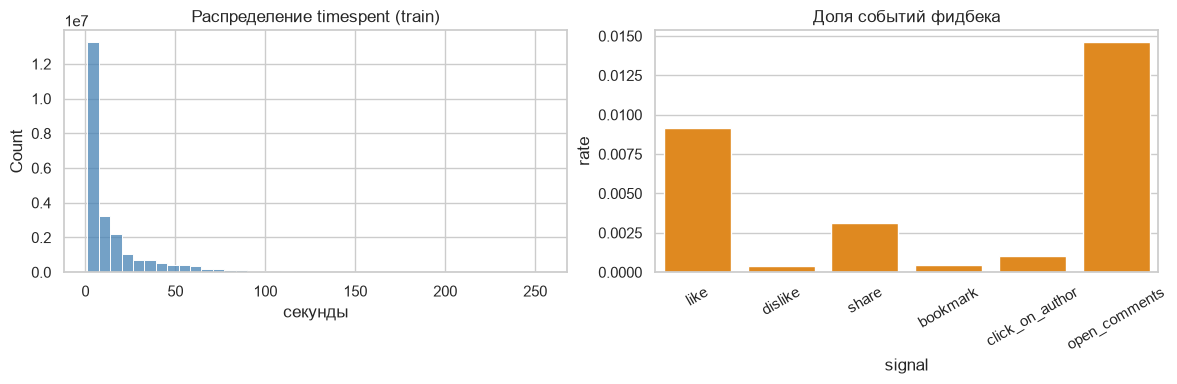

In [5]:
feedback_cols = ["like", "dislike", "share", "bookmark", "click_on_author", "open_comments"]
rates = train_raw.select([pl.col(c).mean().alias(c) for c in feedback_cols] + [pl.col("timespent").mean().alias("timespent_mean"), pl.col("timespent").median().alias("timespent_median")])
print(rates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_raw.select("timespent").to_series().to_numpy(), bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Распределение timespent (train)")
axes[0].set_xlabel("секунды")

rate_df = pd.DataFrame({"signal": feedback_cols, "rate": [float(train_raw[c].mean()) for c in feedback_cols]})
sns.barplot(data=rate_df, x="signal", y="rate", ax=axes[1], color="darkorange")
axes[1].set_title("Доля событий фидбека")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

Интерпретация: медиана просмотра заметно ниже среднего — много быстрых skip.
Явные лайки редки (~1%), поэтому для CF используем комбинированный позитивный сигнал.

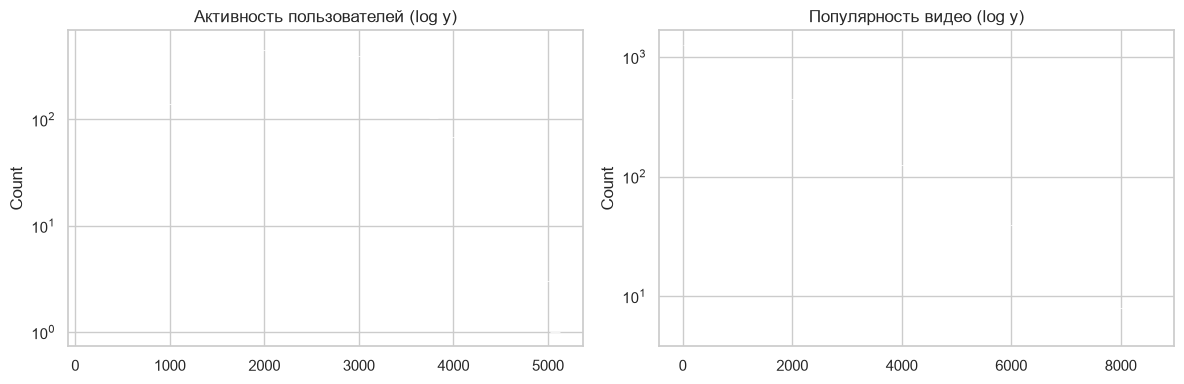

User activity: shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 10000.0    │
│ null_count ┆ 0.0        │
│ mean       ┆ 2387.7602  │
│ std        ┆ 770.198871 │
│ min        ┆ 175.0      │
│ 25%        ┆ 1847.0     │
│ 50%        ┆ 2397.0     │
│ 75%        ┆ 2927.0     │
│ max        ┆ 5123.0     │
└────────────┴────────────┘
Item popularity: shape: (9, 2)
┌────────────┬─────────────┐
│ statistic  ┆ value       │
│ ---        ┆ ---         │
│ str        ┆ f64         │
╞════════════╪═════════════╡
│ count      ┆ 14635.0     │
│ null_count ┆ 0.0         │
│ mean       ┆ 1631.540963 │
│ std        ┆ 1522.009351 │
│ min        ┆ 1.0         │
│ 25%        ┆ 574.0       │
│ 50%        ┆ 1167.0      │
│ 75%        ┆ 2173.0      │
│ max        ┆ 8545.0      │
└────────────┴─────────────┘


In [6]:
user_act = train_raw.group_by("user_id").agg(pl.len().alias("n_inter"))
item_pop = train_raw.group_by("item_id").agg(pl.len().alias("n_inter"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(user_act["n_inter"].to_numpy(), bins=50, log_scale=(False, True), ax=axes[0], color="teal")
axes[0].set_title("Активность пользователей (log y)")
sns.histplot(item_pop["n_inter"].to_numpy(), bins=50, log_scale=(False, True), ax=axes[1], color="purple")
axes[1].set_title("Популярность видео (log y)")
plt.tight_layout()
plt.show()

print("User activity:", user_act["n_inter"].describe())
print("Item popularity:", item_pop["n_inter"].describe())

Интерпретация: выраженный long-tail. MostPop будет сильным baseline на популярном subsample

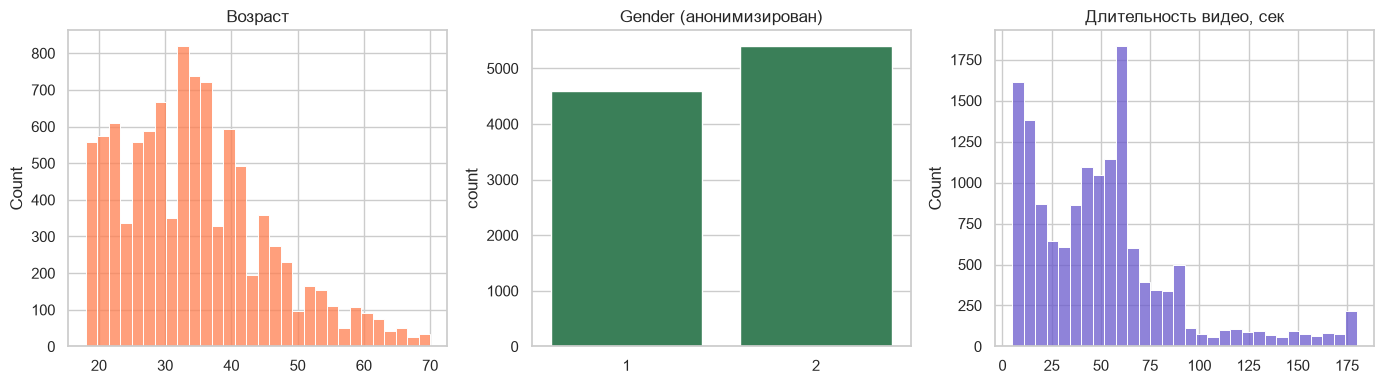

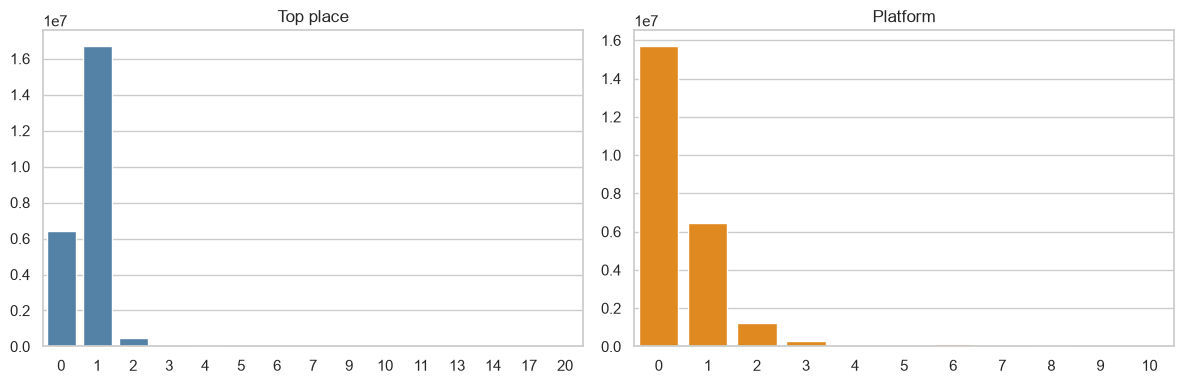

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(users_s["age"].to_numpy(), bins=30, ax=axes[0], color="coral")
axes[0].set_title("Возраст")
sns.countplot(x=users_s["gender"].to_numpy(), ax=axes[1], color="seagreen")
axes[1].set_title("Gender (анонимизирован)")
sns.histplot(items_s["duration"].to_numpy(), bins=30, ax=axes[2], color="slateblue")
axes[2].set_title("Длительность видео, сек")
plt.tight_layout()
plt.show()

place_counts = train_raw.group_by("place").len().sort("len", descending=True).head(15)
platform_counts = train_raw.group_by("platform").len().sort("len", descending=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=place_counts["place"].to_numpy(), y=place_counts["len"].to_numpy(), ax=axes[0], color="steelblue")
axes[0].set_title("Top place")
sns.barplot(x=platform_counts["platform"].to_numpy(), y=platform_counts["len"].to_numpy(), ax=axes[1], color="darkorange")
axes[1].set_title("Platform")
plt.tight_layout()
plt.show()

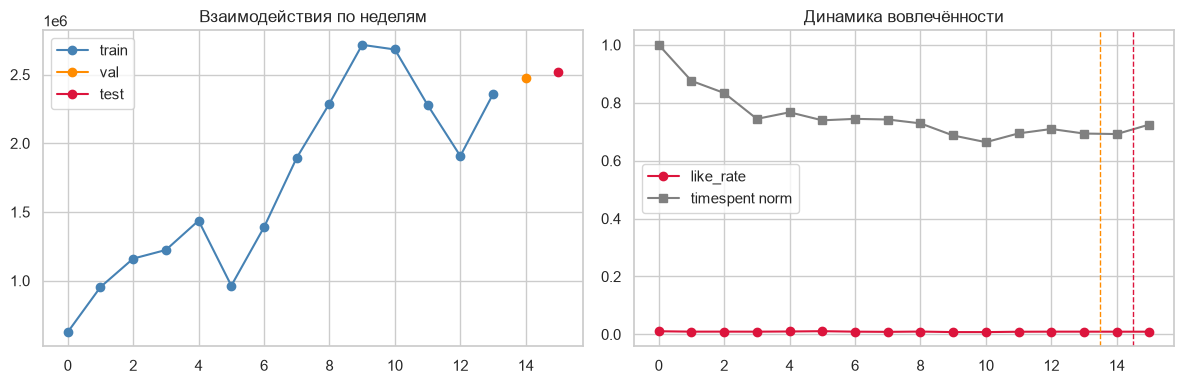

,week,split,n,like_rate,ts_mean
0,0,train,625523,0.010826,21.062644
1,1,train,953185,0.009454,18.440422
2,2,train,1160443,0.009518,17.559423
3,3,train,1223310,0.009372,15.676308
4,4,train,1437122,0.010028,16.156315
5,5,train,963319,0.011030,15.571165
6,6,train,1388849,0.009413,15.676466
7,7,train,1894300,0.008743,15.630739
8,8,train,2288911,0.009718,15.349431
9,9,train,2716364,0.007908,14.467712


In [8]:
week_stats = []
labeled_files = (
    [(f, "train") for f in train_files]
    + [(train_dir / "week_14.parquet", "val"), (train_dir / "week_15.parquet", "test")]
)
for f, split_name in labeled_files:
    week = int(f.stem.split("_")[1])
    w = pl.scan_parquet(str(f)).select([
        pl.len().alias("n"),
        pl.col("like").mean().alias("like_rate"),
        pl.col("timespent").mean().alias("ts_mean"),
    ]).collect()
    week_stats.append({"week": week, "split": split_name, **w.to_dicts()[0]})
week_df = pd.DataFrame(week_stats).sort_values("week")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
colors = {"train": "steelblue", "val": "darkorange", "test": "crimson"}
for split_name, part in week_df.groupby("split", sort=False):
    axes[0].plot(part["week"], part["n"], marker="o", color=colors[split_name], label=split_name)
axes[0].set_title("Взаимодействия по неделям")
axes[0].legend()
axes[1].plot(week_df["week"], week_df["like_rate"], marker="o", color="crimson", label="like_rate")
axes[1].plot(week_df["week"], week_df["ts_mean"] / week_df["ts_mean"].max(), marker="s", color="gray", label="timespent norm")
axes[1].axvline(13.5, color="darkorange", ls="--", lw=1)
axes[1].axvline(14.5, color="crimson", ls="--", lw=1)
axes[1].legend()
axes[1].set_title("Динамика вовлечённости")
plt.tight_layout()
plt.show()
week_df


## 3. Отчёт по качеству данных

In [9]:
def quality_report(df: pl.DataFrame, name: str) -> pd.DataFrame:
    n = df.height
    rows = []
    for c in df.columns:
        nulls = df[c].null_count()
        rows.append({
            "split": name,
            "column": c,
            "dtype": str(df[c].dtype),
            "nulls": int(nulls),
            "null_pct": round(100 * nulls / n, 4),
            "n_unique": int(df[c].n_unique()),
        })
    return pd.DataFrame(rows)

qr = pd.concat(
    [
        quality_report(train_raw, "train"),
        quality_report(val_raw, "val"),
        quality_report(test_raw, "test"),
    ],
    ignore_index=True,
)
display(qr)

def n_dup_pairs(df: pl.DataFrame) -> int:
    pairs = df.select(["user_id", "item_id"])
    return int(pairs.height - pairs.n_unique())

print(
    "Дубли пар (user, item): "
    f"train={n_dup_pairs(train_raw)}, val={n_dup_pairs(val_raw)}, test={n_dup_pairs(test_raw)}"
)

ts = train_raw["timespent"].to_numpy()
q1, q3 = np.percentile(ts, [25, 75])
iqr = q3 - q1
print(f"timespent: Q1={q1}, Q3={q3}, IQR={iqr:.1f}, доля cap=255: {(ts == 255).mean():.4%}")

def n_overlap(left: pl.DataFrame, right: pl.DataFrame, col: str) -> int:
    return left.select(col).unique().join(right.select(col).unique(), on=col).height

print(
    "Пересечение train∩val: "
    f"users={n_overlap(train_raw, val_raw, 'user_id')}, items={n_overlap(train_raw, val_raw, 'item_id')}"
)
print(
    "Пересечение train∩test: "
    f"users={n_overlap(train_raw, test_raw, 'user_id')}, items={n_overlap(train_raw, test_raw, 'item_id')}"
)


,split,column,dtype,nulls,null_pct,n_unique
0,train,user_id,UInt32,0,0.0,10000
1,train,item_id,UInt32,0,0.0,14635
2,train,place,UInt8,0,0.0,24
3,train,platform,UInt8,0,0.0,11
4,train,agent,UInt8,0,0.0,18
5,train,timespent,UInt8,0,0.0,255
6,train,like,Boolean,0,0.0,2
7,train,dislike,Boolean,0,0.0,2
8,train,share,Boolean,0,0.0,2
9,train,bookmark,Boolean,0,0.0,2


Дубли пар (user, item): train=0, val=0, test=0
timespent: Q1=2.0, Q3=17.0, IQR=15.0, доля cap=255: 0.0579%
Пересечение train∩val: users=9992, items=9711
Пересечение train∩test: users=9999, items=9147


Вывод: пропусков нет; дублей пар нет; timespent ограничен сверху 255 (артефакт сбора).
Тяжёлые хвосты популярности — естественный long-tail, не шум.

## 4. Целевая переменная и предобработка

**Объектом рекомендации** выступает короткое видео (`item_id`) конкретному пользователю (`user_id`).

**Позитивная метка `relevant=1`**, если есть явный интерес или достаточно просмотров:
- `like` ∨ `share` ∨ `bookmark`,
- ∨ `timespent >= 15` сек.

Такой сигнал ближе к промышленному implicit feedback для short-video, где лайки редки.

**Сплит:** глобальный временной, три соседние части без пропущенных недель.
- train = `week_00`–`week_13` — матрица для обучения;
- validation = `week_14` — выбор гиперпараметров по NDCG@50;
- test = `week_15` — одна итоговая оценка уже выбранных моделей.


In [10]:
def add_relevance(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        (
            pl.col("like")
            | pl.col("share")
            | pl.col("bookmark")
            | (pl.col("timespent") >= POS_TIMESPENT)
        ).alias("relevant")
    )

train = add_relevance(train_raw)
val = add_relevance(val_raw)
test = add_relevance(test_raw)
train_pos = train.filter(pl.col("relevant"))
val_pos = val.filter(pl.col("relevant"))
test_pos = test.filter(pl.col("relevant"))

print(
    f"relevant rate train={train['relevant'].mean():.4f}, "
    f"val={val['relevant'].mean():.4f}, test={test['relevant'].mean():.4f}"
)
print(f"positives: train={train_pos.height:,}, val={val_pos.height:,}, test={test_pos.height:,}")


relevant rate train=0.2958, val=0.2878, test=0.3103
positives: train=7,063,598, val=712,992, test=781,956


Каталог: айтемы с достаточным числом позитивов в train (убираем шум / холодный хвост)

In [11]:
min_item_freq = 20
item_freq = train_pos.group_by("item_id").agg(pl.len().alias("freq"))
catalog = item_freq.filter(pl.col("freq") >= min_item_freq).select("item_id")
train_pos = train_pos.join(catalog, on="item_id")
val_pos_cf = val_pos.join(catalog, on="item_id")
test_pos_cf = test_pos.join(catalog, on="item_id")
print(f"Каталог айтемов: {catalog.height:,}")


Каталог айтемов: 13,952


Индексы матрицы

In [12]:
users_map = (
    train_pos.select("user_id").unique().sort("user_id")
    .with_row_index("u")
)
items_map = catalog.sort("item_id").with_row_index("i")
n_users = users_map.height
n_items = items_map.height
print(f"Матрица: {n_users} × {n_items}")

Матрица: 10000 × 13952


Train positives → CSR

In [13]:
mapped_pos = train_pos.join(users_map, on="user_id").join(items_map, on="item_id")
rows = mapped_pos["u"].to_numpy().astype(np.int32)
cols = mapped_pos["i"].to_numpy().astype(np.int32)
X = sparse.csr_matrix(
    (np.ones(len(rows), dtype=np.float32), (rows, cols)),
    shape=(n_users, n_items),
)
X.sum_duplicates()
X.data[:] = 1.0
print("X nnz:", X.nnz, f"density={X.nnz / (n_users * n_items):.4%}")

X nnz: 7057960 density=5.0587%


Seen: все показы train по каталогу (CSR mask)

In [14]:
mapped_seen = (
    train.select(["user_id", "item_id"])
    .join(users_map, on="user_id")
    .join(items_map, on="item_id")
)
seen = sparse.csr_matrix(
    (
        np.ones(mapped_seen.height, dtype=np.uint8),
        (mapped_seen["u"].to_numpy(), mapped_seen["i"].to_numpy()),
    ),
    shape=(n_users, n_items),
)
seen.sum_duplicates()
seen.data[:] = 1
print("seen nnz:", seen.nnz)

seen nnz: 23785928


Ground truth

In [15]:
def ground_truth(pos_df: pl.DataFrame) -> dict[int, set[int]]:
    mapped = pos_df.join(users_map, on="user_id").join(items_map, on="item_id")
    grouped = mapped.group_by("u").agg(pl.col("i").alias("items"))
    return {int(r["u"]): set(r["items"]) for r in grouped.iter_rows(named=True)}

gt_val = ground_truth(val_pos_cf)
gt_test = ground_truth(test_pos_cf)
gt = gt_test
eval_user_idx = sorted(gt_test)
print(f"Val users: {len(gt_val):,} | Test users: {len(gt_test):,}")

user_ids = users_map["user_id"].to_numpy()
item_ids = items_map["item_id"].to_numpy()


Val users: 9,969 | Test users: 9,949


## 5. Методы формирования рекомендаций


### 5.1. MostPop
Скор айтема = число позитивных взаимодействий в train. Всем пользователям выдаём общий топ с фильтром уже виденного.

In [16]:
item_pop = np.asarray(X.sum(axis=0)).ravel().astype(np.float64)
mostpop_order = np.argsort(-item_pop)

def recommend_mostpop(u: int, k: int = K) -> np.ndarray:
    mask = np.ones(n_items, dtype=bool)
    mask[seen[u].indices] = False
    recs = mostpop_order[mask[mostpop_order]][:k]
    return recs.astype(np.int32)

print("top item_id:", item_ids[mostpop_order[:5]].tolist())

top item_id: [329362081, 223999892, 156981808, 480101985, 84830224]


### 5.2. ItemKNN
Косинусное сходство столбцов \(X\). Для экономии памяти сходства считаются блоками, для каждого айтема хранятся только top-80 соседей. Скор пользователя: сумма сходств айтемов из его истории.

In [17]:
def fit_itemknn(X_csr: sparse.csr_matrix, topk: int = 80, block: int = 500, verbose: bool = True) -> sparse.csr_matrix:
    Xc = normalize(X_csr.tocsc(), axis=0)
    Xt = Xc.T.tocsr()
    n = Xc.shape[1]
    indptr = [0]
    indices = []
    data = []
    for start in range(0, n, block):
        end = min(start + block, n)
        sim = (Xt[start:end] @ Xc).toarray().astype(np.float32)
        for local, item in enumerate(range(start, end)):
            row = sim[local]
            row[item] = -np.inf
            nn = np.argpartition(row, -topk)[-topk:]
            nn = nn[np.argsort(-row[nn])]
            indices.extend(nn.tolist())
            data.extend(row[nn].tolist())
            indptr.append(len(indices))
        if verbose and start % 2000 == 0:
            print(f"  ItemKNN block {start}-{end}/{n}")
    return sparse.csr_matrix((data, indices, indptr), shape=(n, n), dtype=np.float32)

def recommend_itemknn(u: int, k: int = K) -> np.ndarray:
    scores = X[u].dot(S_knn).toarray().ravel()
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)


### 5.3. PureSVD
Усечённое SVD матрицы взаимодействий. Пользовательский эмбеддинг — строка, айтемный — строка. Скор — скалярное произведение. Это представитель семейства **матричных факторизаций** (рядом с ALS/SVD).

In [18]:
def fit_puresvd(X_csr: sparse.csr_matrix, n_components: int):
    svd_model = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE, n_iter=8)
    users = svd_model.fit_transform(X_csr).astype(np.float32)
    items = svd_model.components_.T.astype(np.float32)
    return users, items, float(svd_model.explained_variance_ratio_.sum())

def recommend_puresvd(u: int, k: int = K) -> np.ndarray:
    scores = user_factors[u] @ item_factors.T
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)


## 6. Метрики качества

| Метрика | Тип | Смысл |
|---------|-----|--------|
| Precision@K | relevance | доля релевантных в top-K |
| Recall@K | relevance | доля найденных релевантных |
| **NDCG@K** | **ранжирование** | учитывает позицию |
| **MAP@K** | **ранжирование** | средняя точность по рангу |
| **Novelty@K** | **специфика recsys** | средняя самоинформация айтемов списка |
| Coverage | специфика recsys | доля уникальных айтемов в выдаче |

В тестовой неделе у пользователя десятки релевантных видео, поэтому один срез K=10 почти обнуляет Recall и плохо разделяет методы. Метрики считаются при **K ∈ {10, 20, 50, 100}** по одному и тому же ранжированию длины 100. Основной срез и подбор гиперпараметров — **K=50**. Итоговые числа — на test (`week_15`).

**Novelty@K** показывает, насколько список уходит из головы каталога в длинный хвост. Для айтема $i$

$$P(i)=\frac{m_i}{N},\qquad \mathrm{info}(i)=-\log_2 P(i)=\log_2\frac{N}{m_i},$$

где $m_i$ — число пользователей train, которым показали $i$, а $N$ — число пользователей train. У топ-хита $m_i\approx N$ и $\mathrm{info}(i)\to 0$. У редкого айтема $\mathrm{info}(i)$ большое. По списку рекомендаций $R$

$$Novelty=\frac{1}{|R|}\sum_{i\in R}\mathrm{info}(i).$$

MostPop без фильтра уже виденного ставит в список самые известные айтемы, и его Novelty близка к нулю. Очень высокая Novelty сама по себе не лучше: в хвосте много слабых видео, поэтому её читают вместе с NDCG.


In [19]:
shown = np.asarray(seen.sum(axis=0)).ravel().astype(np.float64)
p_item = np.clip(shown / n_users, 1.0 / n_users, 1.0)
item_novelty = -np.log2(p_item)

def precision_at_k(recs, truth, k):
    return len(set(recs[:k]) & truth) / k

def recall_at_k(recs, truth, k):
    return len(set(recs[:k]) & truth) / len(truth) if truth else 0.0

def ndcg_at_k(recs, truth, k):
    if not truth:
        return 0.0
    dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(recs[:k]) if it in truth)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(truth), k)))
    return dcg / idcg if idcg else 0.0

def ap_at_k(recs, truth, k):
    if not truth:
        return 0.0
    hits, s = 0, 0.0
    for i, it in enumerate(recs[:k]):
        if it in truth:
            hits += 1
            s += hits / (i + 1)
    return s / min(len(truth), k)

def novelty_at_k(recs, k):
    return float(np.mean(item_novelty[list(recs[:k])])) if len(recs) else 0.0

def mean_ndcg(recommend_fn, truth: dict, k: int = K) -> float:
    users = list(truth)
    if not users:
        return 0.0
    return float(np.mean([ndcg_at_k(recommend_fn(u, k), truth[u], k) for u in users]))

def evaluate_at_ks(recommend_fn, user_indices, name: str, ks=K_LIST) -> pd.DataFrame:
    ks = tuple(sorted(ks))
    max_k = ks[-1]
    buckets = {k: {m: [] for m in ["precision", "recall", "ndcg", "map", "novelty"]} for k in ks}
    covered = {k: [] for k in ks}
    for u in user_indices:
        recs = list(recommend_fn(u, max_k))
        truth = gt[u]
        for k in ks:
            buckets[k]["precision"].append(precision_at_k(recs, truth, k))
            buckets[k]["recall"].append(recall_at_k(recs, truth, k))
            buckets[k]["ndcg"].append(ndcg_at_k(recs, truth, k))
            buckets[k]["map"].append(ap_at_k(recs, truth, k))
            buckets[k]["novelty"].append(novelty_at_k(recs, k))
            covered[k].extend(recs[:k])
    rows = []
    for k in ks:
        row = {m: float(np.mean(v)) for m, v in buckets[k].items()}
        row["coverage"] = len(set(covered[k])) / n_items
        row["model"] = name
        row["k"] = k
        rows.append(row)
        print(f"{name} @{k}", {m: round(row[m], 5) for m in ["precision", "recall", "ndcg", "map", "novelty", "coverage"]})
    return pd.DataFrame(rows)

print(f"Test users: {len(eval_user_idx)}, validation users: {len(gt_val)}, основной K={K}, срезы={K_LIST}")


Test users: 9949, validation users: 9969, основной K=50, срезы=(10, 20, 50, 100)


### 6.1. Подбор гиперпараметров на validation

Модели обучаются на `week_00`–`week_13`. На `week_14` по NDCG@50 выбираются:
- число соседей ItemKNN (`topk`);
- число компонент PureSVD (`n_components`).

MostPop параметров не имеет и в перебор не входит. `week_15` на этом шаге не используется. В итоговый test попадает та модель, которая уже выиграла на validation, без дообучения на `week_14`.


In [20]:
def recommend_from_similarity(S: sparse.csr_matrix, u: int, k: int = K) -> np.ndarray:
    scores = X[u].dot(S).toarray().ravel()
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)

def recommend_from_factors(users, items, u: int, k: int = K) -> np.ndarray:
    scores = users[u] @ items.T
    scores[seen[u].indices] = -np.inf
    top = np.argpartition(-scores, k)[:k]
    return top[np.argsort(-scores[top])].astype(np.int32)

tuning_rows = []
print(f"MostPop validation NDCG@{K}: {mean_ndcg(recommend_mostpop, gt_val):.5f}")

best_knn = None
for topk in (40, 80, 160):
    S = fit_itemknn(X, topk=topk, block=500, verbose=False)
    score = mean_ndcg(lambda u, k, S=S: recommend_from_similarity(S, u, k), gt_val)
    tuning_rows.append({"model": "ItemKNN", "param": "topk", "value": topk, "val_ndcg": score})
    print(f"ItemKNN topk={topk}: validation NDCG@{K}={score:.5f}")
    if best_knn is None or score > best_knn[0]:
        best_knn = (score, topk, S)

best_svd = None
for rank in (32, 64, 128):
    users, items, explained = fit_puresvd(X, rank)
    score = mean_ndcg(lambda u, k, users=users, items=items: recommend_from_factors(users, items, u, k), gt_val)
    tuning_rows.append({"model": "PureSVD", "param": "n_components", "value": rank, "val_ndcg": score})
    print(f"PureSVD n_components={rank}: validation NDCG@{K}={score:.5f}, explained={explained:.3f}")
    if best_svd is None or score > best_svd[0]:
        best_svd = (score, rank, users, items, explained)

_, best_knn_topk, S_knn = best_knn
_, best_svd_rank, user_factors, item_factors, svd_explained = best_svd
print(f"Выбрано: ItemKNN topk={best_knn_topk}, PureSVD n_components={best_svd_rank}")
print(f"PureSVD explained variance: {svd_explained:.3f}")
print("S nnz:", S_knn.nnz)

tuning_df = pd.DataFrame(tuning_rows)
tuning_df


MostPop validation NDCG@50: 0.00608
ItemKNN topk=40: validation NDCG@50=0.01188
ItemKNN topk=80: validation NDCG@50=0.01173
ItemKNN topk=160: validation NDCG@50=0.01158
PureSVD n_components=32: validation NDCG@50=0.02041, explained=0.147
PureSVD n_components=64: validation NDCG@50=0.02262, explained=0.175
PureSVD n_components=128: validation NDCG@50=0.02348, explained=0.208
Выбрано: ItemKNN topk=40, PureSVD n_components=128
PureSVD explained variance: 0.208
S nnz: 558080


,model,param,value,val_ndcg
0,ItemKNN,topk,40,0.011880
1,ItemKNN,topk,80,0.011732
2,ItemKNN,topk,160,0.011584
3,PureSVD,n_components,32,0.020411
4,PureSVD,n_components,64,0.022620
5,PureSVD,n_components,128,0.023482


In [21]:
model_fns = [
    (recommend_mostpop, "MostPop"),
    (recommend_itemknn, f"ItemKNN (topk={best_knn_topk})"),
    (recommend_puresvd, f"PureSVD (rank={best_svd_rank})"),
]
results_long = pd.concat(
    [evaluate_at_ks(fn, eval_user_idx, name) for fn, name in model_fns],
    ignore_index=True,
)
results_df = (
    results_long.loc[results_long["k"] == K]
    .set_index("model")[["precision", "recall", "ndcg", "map", "novelty", "coverage"]]
)
print(f"NDCG по K:\n{results_long.pivot(index='model', columns='k', values='ndcg').round(5)}")
print(f"Recall по K:\n{results_long.pivot(index='model', columns='k', values='recall').round(5)}")
results_df


MostPop @10 {'precision': 0.00542, 'recall': 0.00148, 'ndcg': 0.00544, 'map': 0.00161, 'novelty': 0.91373, 'coverage': 0.00839}
MostPop @20 {'precision': 0.00522, 'recall': 0.00282, 'ndcg': 0.00546, 'map': 0.00104, 'novelty': 0.94712, 'coverage': 0.01627}
MostPop @50 {'precision': 0.00533, 'recall': 0.00731, 'ndcg': 0.00682, 'map': 0.00077, 'novelty': 0.98221, 'coverage': 0.02982}
MostPop @100 {'precision': 0.00484, 'recall': 0.01311, 'ndcg': 0.00924, 'map': 0.00079, 'novelty': 1.04433, 'coverage': 0.04888}
ItemKNN (topk=40) @10 {'precision': 0.00892, 'recall': 0.00218, 'ndcg': 0.00945, 'map': 0.00298, 'novelty': 1.06043, 'coverage': 0.02215}
ItemKNN (topk=40) @20 {'precision': 0.00902, 'recall': 0.00449, 'ndcg': 0.00955, 'map': 0.00194, 'novelty': 1.20095, 'coverage': 0.03928}
ItemKNN (topk=40) @50 {'precision': 0.0097, 'recall': 0.01257, 'ndcg': 0.01202, 'map': 0.00142, 'novelty': 1.42814, 'coverage': 0.08816}
ItemKNN (topk=40) @100 {'precision': 0.01092, 'recall': 0.02836, 'ndcg': 0

,precision,recall,ndcg,map,novelty,coverage
model,,,,,,
MostPop,0.005327,0.007312,0.006825,0.000766,0.982210,0.029817
ItemKNN (topk=40),0.009697,0.012569,0.012021,0.001415,1.428143,0.088159
PureSVD (rank=128),0.015965,0.023187,0.020471,0.002678,1.848068,0.489966


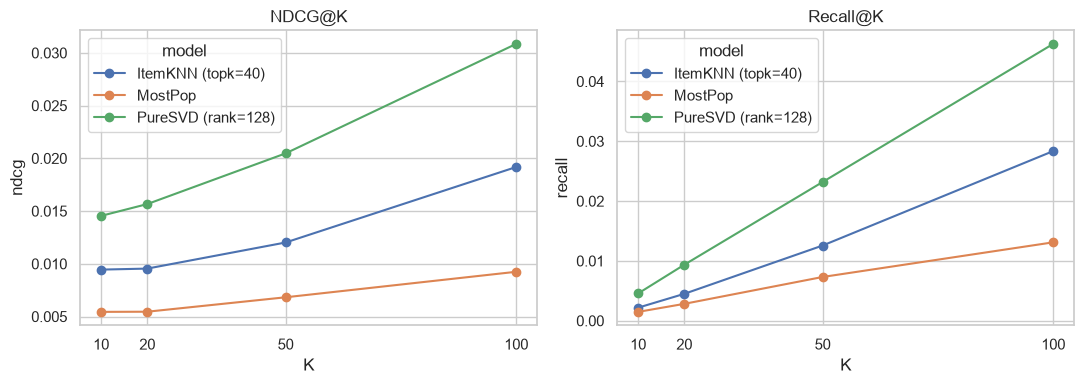

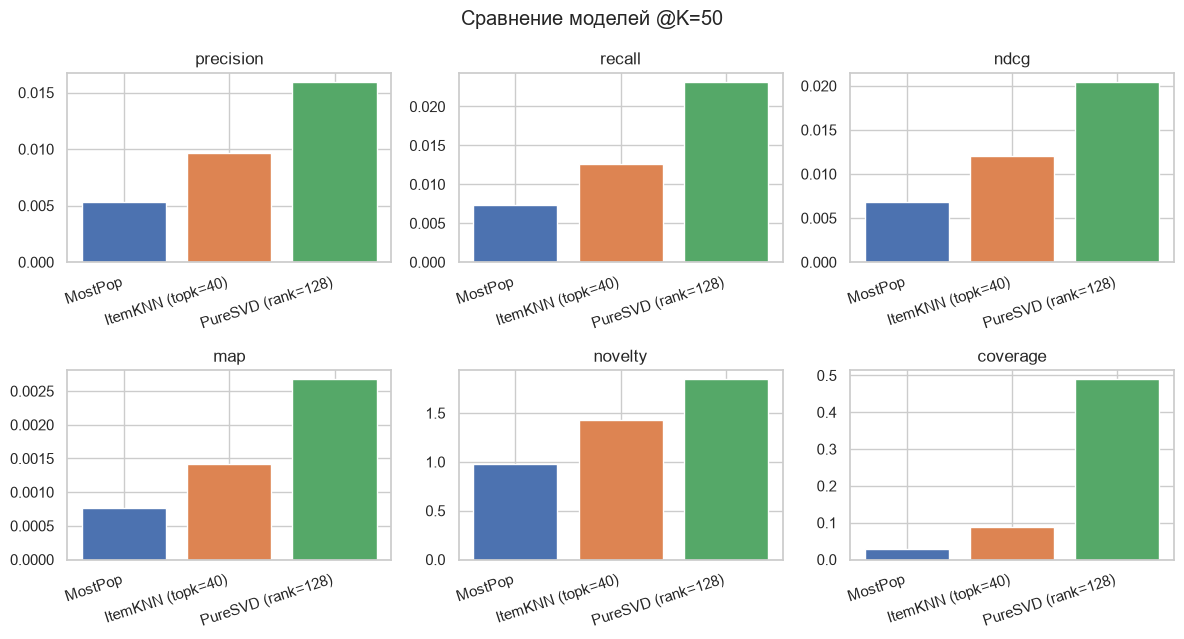

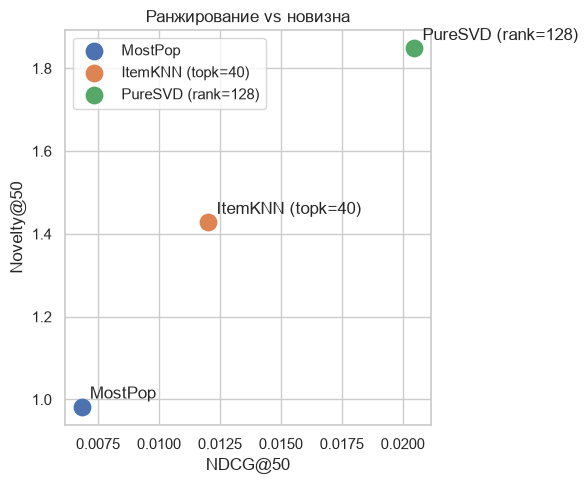

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ("ndcg", "recall")):
    wide = results_long.pivot(index="k", columns="model", values=metric)
    wide.plot(marker="o", ax=ax)
    ax.set_xlabel("K")
    ax.set_ylabel(metric)
    ax.set_xticks(list(K_LIST))
    ax.set_title(f"{metric.upper()}@K" if metric == "ndcg" else "Recall@K")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
palette = sns.color_palette("deep", n_colors=len(results_df))
for ax, metric in zip(axes.ravel(), results_df.columns):
    ax.bar(range(len(results_df)), results_df[metric], color=palette)
    ax.set_xticks(range(len(results_df)))
    ax.set_xticklabels(results_df.index, rotation=18, ha="right")
    ax.set_title(metric)
    ax.set_ylabel("")
fig.suptitle(f"Сравнение моделей @K={K}")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
for model, r in results_df.iterrows():
    ax.scatter(r["ndcg"], r["novelty"], s=140, label=model)
    ax.annotate(model, (r["ndcg"], r["novelty"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel(f"NDCG@{K}")
ax.set_ylabel(f"Novelty@{K}")
ax.set_title("Ранжирование vs новизна")
ax.legend()
plt.tight_layout()
plt.show()


## 7. Интерпретация результатов

In [23]:
best_ndcg = results_df["ndcg"].idxmax()
best_nov = results_df["novelty"].idxmax()
best_cov = results_df["coverage"].idxmax()
print(f"Лучший NDCG@{K}: {best_ndcg} ({results_df.loc[best_ndcg, 'ndcg']:.5f})")
print(f"Лучшая Novelty@{K}: {best_nov} ({results_df.loc[best_nov, 'novelty']:.5f})")
print(f"Лучший Coverage: {best_cov} ({results_df.loc[best_cov, 'coverage']:.5f})")
print()
for model, r in results_df.iterrows():
    print(
        f"- {model}: P={r['precision']:.4f}, R={r['recall']:.4f}, "
        f"NDCG={r['ndcg']:.4f}, MAP={r['map']:.4f}, "
        f"Novelty={r['novelty']:.4f}, Coverage={r['coverage']:.4f}"
    )

Лучший NDCG@50: PureSVD (rank=128) (0.02047)
Лучшая Novelty@50: PureSVD (rank=128) (1.84807)
Лучший Coverage: PureSVD (rank=128) (0.48997)

- MostPop: P=0.0053, R=0.0073, NDCG=0.0068, MAP=0.0008, Novelty=0.9822, Coverage=0.0298
- ItemKNN (topk=40): P=0.0097, R=0.0126, NDCG=0.0120, MAP=0.0014, Novelty=1.4281, Coverage=0.0882
- PureSVD (rank=128): P=0.0160, R=0.0232, NDCG=0.0205, MAP=0.0027, Novelty=1.8481, Coverage=0.4900


Интерпретация по полученным метрикам на `week_15`. Параметры ItemKNN (`topk`) и PureSVD (`n_components`) зафиксированы по лучшему NDCG@50 на `week_14`. На test сетка заново не перебирается.

Метрики показаны при K = 10, 20, 50 и 100. K=10 оставлен как короткий срез ленты, но основной вывод делается по K=50: при десятке позиций Recall на недельном тесте слишком мал, чтобы сравнивать методы. С ростом K Recall и NDCG растут, потому что в выдачу попадает больше релевантных видео; порядок методов нужно читать и по кривой, и по таблице @50.

- MostPop выдаёт почти один список всем пользователям, поэтому Coverage у него минимальный. Свободных параметров у него нет, на validation он только задаёт ориентир.
- ItemKNN при выбранном числе соседей переносит сигнал с похожих видео из истории. Малый `topk` сужает выдачу, большой размывает соседей.
- PureSVD при выбранной размерности обобщает ту же матрицу шире локальных соседей, пока дополнительные компоненты не начинают повторять шум train.
- Недели 13, 14 и 15 идут подряд. Разница методов — это качество ранжирования на следующей неделе.


## 8. Предложения по улучшению качества рекомендаций

1. **Калибровка релевантности**: нормировать `timespent` на `duration` (доля досмотра); добавить `open_comments` / `click_on_author`.
2. **Гибриды**: blending MostPop + PureSVD / ItemKNN; переранжирование кандидатов контентными эмбеддингами VK-LSVD.
3. **Временное затухание**: больший вес свежим взаимодействиям (интересы в short-video быстро дрейфуют).
4. **Two-stage**: retrieval (CF + popularity) → learning-to-rank на контексте `place/platform/agent`.
5. **Cold-start**: отдельные стратегии для новых видео/авторов по контенту и метаданным.
6. **Протокол оценки**: next-item / session-based метрики и Intra-List Diversity.
7. **Масштаб данных**: больше недель (15–24) или subsample `ur0.01_ir0.01`.

## 9. Итоговые выводы

1. EDA показал skip-heavy поведение, редкие явные лайки, long-tail популярности; пропусков и дублей пар нет.
2. Целевая сущность — **рекомендация короткого видео**; целевой сигнал — комбинированная релевантность.
3. Реализованы **MostPop**, **ItemKNN** и **PureSVD**. `topk` и `n_components` выбраны по NDCG@50 на `week_14`. На `week_15` метрики посчитаны при K = 10, 20, 50 и 100; основной срез — K=50.
4. Сравнение метрик выявляет компромисс «точность хитов ↔ новизна/покрытие»; дальнейший рост качества — за гибридными и двухэтапными схемами.
